# Promoting `dyn_activity` / `dyn_excess` to the primary phenotypic readout

**Checkpoint 3-July-2026 §F / §I' action D1.** This notebook is a *reinterpretation*
of probes EvoCA already ships — no C code, no dynamics change.

## The problem (§F)

The full-genome `activity` probe keys on an FNV-1a hash of the **whole** 250-bit LUT.
Flipping a bit for an input a cell never encounters mints a "new species" **without
changing behaviour** — *silent churn*. So `activity` over-reports phenotypic change.

`dyn_activity` already counts only the **500 `(LUT-input, output)` transitions that
actually fired for alive cells** — a per-*used-entry* signal by construction. The
recommendation is therefore not to *build* anything but to **promote `dyn_activity`
(+ its fixed-space `dyn_excess`) to the primary phenotypic-evolution readout and demote
full-genome `activity` to a churn diagnostic**.

## The key contrast

> full-genome activity churns **and** `dyn_activity` stays concentrated ⇒ **silent churn**
> full-genome activity churns **and** `dyn_activity` also moves ⇒ **real functional change**

The robust discriminator we use is **`dyn_eff`** — the *effective number of exercised
transitions* (a participation ratio over the 500 buckets). Its converged **level** is what
gates the verdict: the population that is genuinely evolving *recruits* transitions and
settles at a high `dyn_eff` (~200/500); the silently-churning population stays **concentrated**
on a small, fixed set (~25/500). We gate on the *level* rather than the growth *slope*
because slope is transient-dependent (a functional run's slope is high early, ~0 once it
plateaus) whereas the converged level is horizon-robust. (`dyn_excess_pc` is reported but is
artifact-prone in sparse/frozen regimes, so it corroborates, it does not gate.)

**The two regimes** (equal `mu_lut=0.03`, so mutation pressure is identical — only the
resource regime differs):
- *functional (rich)*: abundant food → a lively, spreading population that keeps bringing
  new `(input,output)` transitions into use.
- *silent-churn (converged)*: leaner food/tax → the population **converges** to a fixed
  effective rule, after which the only ongoing full-genome `activity` is **neutral drift on
  LUT entries the fixed rule never queries** — the textbook silent churn of §F.


In [1]:
import os, sys
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, 'C', 'evoca.h')):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, 'python'))
import numpy as np
import matplotlib.pyplot as plt
from dyn_analysis import dyn_report, print_report

# Two regimes at EQUAL LUT mutation rate (mu_lut=0.03) so the only thing
# that differs is the resource regime, not the mutation pressure.
CONFIGS = {
    'silent-churn (converged)': dict(food_inc=0.05, m_scale=1.0, tax=0.05,
                                     mu_lut=0.03, mu_egenome=0.0),
    'functional (rich)':        dict(food_inc=0.20, m_scale=1.0, tax=0.02,
                                     mu_lut=0.03, mu_egenome=0.0),
}
RUN = dict(n_steps=1500, sample_every=50, N=96, seed=2)
print('run controls:', RUN)


run controls: {'n_steps': 1500, 'sample_every': 50, 'N': 96, 'seed': 2}


In [2]:
# ~2-3 s per config. dyn_report runs the sim headless and returns
# time-series + summary + a verdict.
reports = {name: dyn_report(cfg, **RUN) for name, cfg in CONFIGS.items()}
for name, rep in reports.items():
    print('=' * 68)
    print_report(rep)


config: {'food_inc': 0.05, 'm_scale': 1.0, 'tax': 0.05, 'mu_lut': 0.03, 'mu_egenome': 0.0}
  run: N=96 steps=1500 seed=2 pop mean/min/final=7833/4608/7950
  CHURN  (full-genome activity -- demoted to diagnostic):
    genome_new_rate     = 1049 new species / 1000 steps  (>0 => activity churning)
    genome_turnover     = 0.81 population-worths of distinct genomes minted
  FUNCTION  (dyn_activity -- PRIMARY readout):
    dyn_eff (final)     = 26.5 / 500 effective transitions  (slope +1.52/kstep)
    dyn_support (final) = 500 / 500 transitions ever used
    dyn_excess_pc final = 1761.55  (corroborating only; artifact-prone when sparse)
  VERDICT: SILENT-CHURN
    activity minting 1049 species/kstep (churning) but dyn_activity concentrated (26/500 effective < 60, slope +1.5/kstep): genome hashes churn while used transitions stay put => SILENT churn
config: {'food_inc': 0.2, 'm_scale': 1.0, 'tax': 0.02, 'mu_lut': 0.03, 'mu_egenome': 0.0}
  run: N=96 steps=1500 seed=2 pop mean/min/final=9067

## The figure

Left — **CHURN track** (full-genome `activity`, *demoted*): cumulative distinct genome
hashes ever seen. Both regimes keep minting new "species" → by this measure alone the two
are indistinguishable.

Centre — **FUNCTION track** (`dyn_activity`, *promoted*): `dyn_eff`, the effective number
of exercised transitions. This is the discriminator — it **climbs** for the functional
regime and stays **flat & low** for the silent-churn regime.

Right — corroborating `dyn_excess_pc` (caveated: artifact-prone when sparse).


saved dyn-promote-demo_fig.png


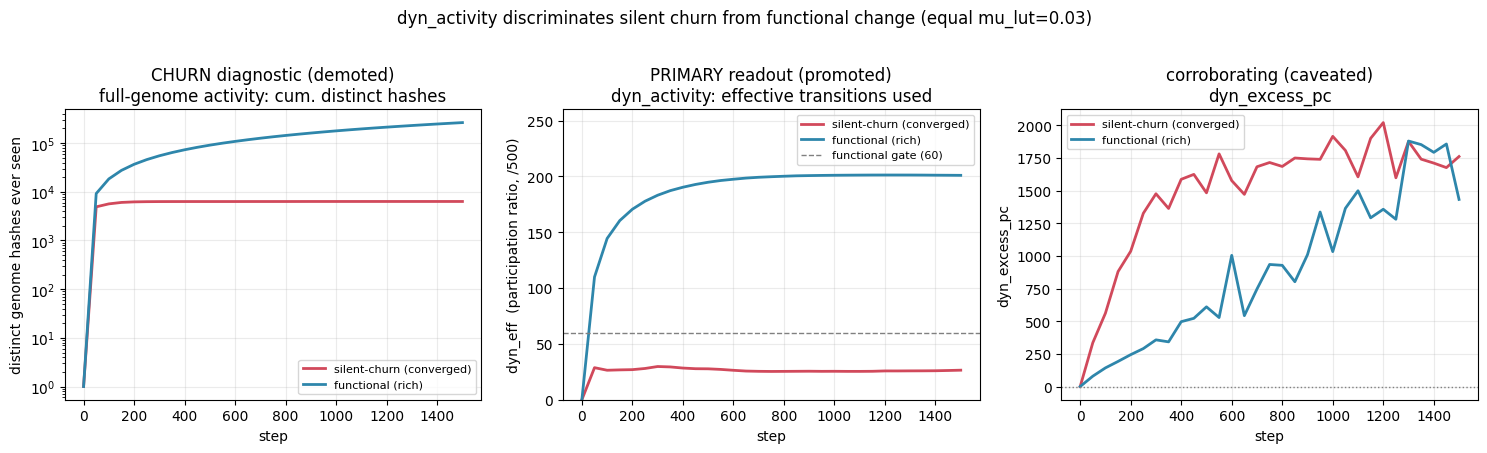

In [3]:
COLORS = {'silent-churn (converged)': '#d1495b', 'functional (rich)': '#2e86ab'}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))

for name, rep in reports.items():
    t = rep['t']; c = COLORS[name]
    ax[0].plot(t, rep['genome_cum_distinct'], color=c, lw=2, label=name)
    ax[1].plot(t, rep['dyn_eff'], color=c, lw=2, label=name)
    ax[2].plot(t, rep['dyn_excess_pc'], color=c, lw=2, label=name)

ax[0].set_title('CHURN diagnostic (demoted)\nfull-genome activity: cum. distinct hashes')
ax[0].set_ylabel('distinct genome hashes ever seen')
ax[0].set_yscale('log')

ax[1].set_title('PRIMARY readout (promoted)\ndyn_activity: effective transitions used')
ax[1].set_ylabel('dyn_eff  (participation ratio, /500)')
gate = list(reports.values())[0]['func_eff_level']
ax[1].axhline(gate, ls='--', color='grey', lw=1,
              label=f'functional gate ({gate:.0f})')
ax[1].set_ylim(0, 260)

ax[2].set_title('corroborating (caveated)\ndyn_excess_pc')
ax[2].set_ylabel('dyn_excess_pc')
ax[2].axhline(0, ls=':', color='grey', lw=1)

for a in ax:
    a.set_xlabel('step'); a.legend(fontsize=8); a.grid(alpha=0.25)

fig.suptitle('dyn_activity discriminates silent churn from functional change '
             '(equal mu_lut=0.03)', fontsize=12, y=1.02)
fig.tight_layout()
OUT = 'dyn-promote-demo_fig.png'
fig.savefig(OUT, dpi=110, bbox_inches='tight')
print('saved', OUT)
plt.show()


In [4]:
# Verdict summary table
print(f"{'config':26s} {'churn/kstep':>12s} {'dyn_eff':>8s} "
      f"{'eff_slope':>10s} {'verdict':>16s}")
print('-' * 76)
for name, rep in reports.items():
    print(f"{name:26s} {rep['genome_new_rate']:12.0f} "
          f"{rep['dyn_eff_final']:8.0f} {rep['dyn_eff_slope']:+10.1f} "
          f"{rep['verdict']:>16s}")


config                      churn/kstep  dyn_eff  eff_slope          verdict
----------------------------------------------------------------------------
silent-churn (converged)           1049       26       +1.5     silent-churn
functional (rich)                176005      201      +52.8       functional


## Reading the result

Both regimes **churn** by the full-genome `activity` measure — the left panel shows both
minting new genome hashes (the converged regime at a lower absolute rate, but still a
continuous drip of "new species"). If you only watched `activity`, you would call **both**
"evolutionarily active".

The centre panel breaks the tie. In the **functional (rich)** regime `dyn_eff` climbs and
settles high (~200 of 500 effective transitions) — the population recruited a broad set of
`(input, output)` transitions into use, i.e. the *effective rule* genuinely changed. In the
**silent-churn (converged)** regime `dyn_eff` sits low and flat (~25 of 500): the population
converged to a fixed effective rule, so the genome-hash churn that continues afterwards is
**neutral drift on LUT entries that rule never queries** — churn with no phenotypic content.
That is silent churn, made visible. We gate on the converged **level** (dashed line), which
is horizon-robust, rather than the growth slope (transient-dependent).

**Take-away (D1 done):** `dyn_activity`'s effective-transition **level** is the primary
phenotypic-evolution readout; full-genome `activity` is retained only as a churn diagnostic
whose *disagreement* with `dyn_activity` is exactly what flags silent churn. `dyn_excess_pc`
corroborates but must not be read raw in sparse/frozen regimes (right panel: it runs erratic
/ negative for the converged run — the known frozen-substrate artifact). An extinction guard
(min/final population) prevents a mid-run die-off — whose frozen metrics mimic "concentrated
+ churning" — from being mislabelled silent churn.
